# Aprendizaje de Simbolo: `ParabolicMLPSymbol` con datos GRF (laplaciano fraccionario 1D)

Mismo experimento que `03_barrido_grf.ipynb` con la referencia $a(\mathbf{k})=|\mathbf{k}|^\alpha$
(`FractionalLaplacianSymbol`, $n=1$) para $\alpha\in\{0.5,\ 1,\ 1.5\}$, aprendiendo con orden $m=\alpha$
($\rho=n+1=2$ para el simbolo aprendido). Hay una seccion por $\alpha$ y, al final, una tabla resumen.

**Funcion de perdida** (la misma de 03)

$$\mathcal{L} = \lambda_{\text{traj}}\,\mathcal{L}_{\text{traj}} + \lambda_{\text{par}}\,\mathcal{L}_{\text{par}} + \lambda_{\text{class}}\,\mathcal{L}_{\text{class}}$$

- **Trayectoria:** $\mathcal{L}_{\text{traj}} = \mathbb{E}\big[|e^{-t a_\theta(\mathbf{k})}\hat u_0(\mathbf{k}) - \hat u_{\text{ref}}(\mathbf{k},t)|^2\big]$
- **Parabolicidad (Def. 2.3):** $\mathcal{L}_{\text{par}} = \mathbb{E}\big[\max\big(0,\ |(a_\theta(\mathbf{k})+\lambda)^{-1}| - \kappa(1+|(\mathbf{k},\lambda)|^2)^{-m/2}\big)^2\big]$,
  sobre $\mathrm{Re}(\lambda)\ge 0$, $|(\mathbf{k},\lambda)|\ge\omega$.
- **Clase de simbolo $S^{m,\rho}$:**
  $\mathcal{L}_{\text{class}} = \mathbb{E}_{\mathbf{k}}\Big[\frac{1}{|A_\rho|}\sum_{\alpha\in A_\rho}\max\big(0,\ \langle\mathbf{k}\rangle^{|\alpha|-m}\,|\Delta^\alpha_k a_\theta(\mathbf{k})| - C_\alpha\big)^2\Big]$,
  con $A_\rho=\{\alpha\in\mathbb{N}_0^n : |\alpha|\le\rho\}$ y $\langle\mathbf{k}\rangle=(1+|\mathbf{k}|^2)^{1/2}$.

# Setup
Configuracion identica a `03_barrido_grf.ipynb`; el codigo de cada seccion esta en
`parabolic_symbol.learning.experiment.GRFExperiment`.

- **Datos (`data/grf.py`):** toro $\mathbb{T}^1=[0,2\pi)^1$, $u(x)=\sum_k \hat u(k)e^{ik\cdot x}$,
  $u_0\sim\mathcal N\big(0,\ 7^4(-\Delta+7^2)^{-2.5}\big)$ en una malla de $1024$ puntos.
  Entrenamiento: $100$ condiciones iniciales, $t=0.05+0.1j$, $j=0,\dots,9$. Prueba: $20$ condiciones
  iniciales nuevas, $t=0.05+0.05j$, $j=0,\dots,19$.
- **Mascara de recuperabilidad:** se descartan los pares $(k,t)$ con $e^{-t\,a(k)}\le\varepsilon_{\texttt{float64}}$,
  y los $k$ con $|k|_\infty > k_{\text{cap}} = 64$. La ventana de $k$ que queda fija $k_{\max}$.
  Particion entrenamiento / validacion **por $\mathbf{k}$** (80% / 20% de los $k$ unicos).
- **$\kappa$:** $\kappa=$ `theoretical_kappa()`, con $c$ y $C$ estimados de los datos de entrenamiento
  (`estimate_symbol` + `estimate_bounds`, $\delta=0.1$) con $m=\alpha$. Las $C_\alpha$ de $\mathcal{L}_{\text{class}}$
  salen del simbolo analitico en $|k_i|\le k_{\max}$, con margen $1.5$.
- **Barrido:** $\{2,3,4\}$ capas ocultas $\times$ $\{32,64,128\}$ neuronas $\times$ dropout $0.2$ en `none` /
  `middle` $\times$ weight decay $\{0,\ 10^{-4}\}$, con **early stopping** sobre la perdida total de validacion
  (trayectoria + parabolicidad + $\mathcal{L}_{\text{class}}$). Se elige la corrida de menor error relativo de validacion.
- `cuda` si esta disponible y `float64`.

In [1]:
from pathlib import Path

import torch

from parabolic_symbol.symbols.heat import HeatSymbol
from parabolic_symbol.symbols.fractional_laplacian import FractionalLaplacianSymbol
from parabolic_symbol.learning.experiment import GRFExperiment, summary_table
from parabolic_symbol.utils import default_device

device = default_device()
dtype = torch.float64
print(f"device = {device}  |  dtype = {dtype}")

RESULTS = Path("../results/05_fraccionario_1d")   # tablas (CSV) y figuras (PNG)
RESULTS.mkdir(parents=True, exist_ok=True)

device = cuda  |  dtype = torch.float64


In [2]:
ALPHAS = [0.5, 1.0, 1.5]
experimentos = {
    alpha: GRFExperiment(
        reference=FractionalLaplacianSymbol(n=1, alpha=alpha), m=alpha, resolution=1024, k_cap=64,
        results=RESULTS / f"alpha_{alpha:g}", dtype=dtype, device=device,
    )
    for alpha in ALPHAS
}

# $\alpha = 0.5$

$a(\mathbf{k})=|\mathbf{k}|^{0.5}$, $m=0.5$, malla 1024 puntos, $k_{\text{cap}}=64$. Tablas y figuras en `results/05_fraccionario_1d/alpha_0.5/`.

In [3]:
exp_0_5 = experimentos[0.5]

## 1. Datos de referencia

Ventana de $k$ resultante y numero de muestras por conjunto.

In [4]:
display(exp_0_5.load_data())

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1290 de 10240 pares (k, t) recuperables (eps=2.22e-16, |k|_inf <= 64) -> 129,000 muestras
  ventana de k recuperable: 129 k, |k|_inf <= 64, |k| in [0, 64]
  max |k| por tiempo: t=0.05:64, t=0.15:64, t=0.25:64, t=0.35:64, t=0.45:64, t=0.55:64, t=0.65:64, t=0.75:64, t=0.85:64, t=0.95:64
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2580 de 20480 pares (k, t) recuperables (eps=2.22e-16, |k|_inf <= 64) -> 51,600 muestras
  ventana de k recuperable: 129 k, |k|_inf <= 64, |k| in [0, 64]
  max |k| por tiempo: t=0.05:64, t=0.10:64, t=0.15:64, t=0.20:64, t=0.25:64, t=0.30:64, t=0.35:64, t=0.40:64, t=0.45:64, t=0.50:64, t=0.55:64, t=0.60:64, t=0.65:64, t=0.70:64, t=0.75:64, t=0.80:64, t=0.85:64, t=0.90:64, t=0.95:64, t=1.00:64

k_cap = 64  ->  k_max = 64  (ventana recuperable: 129 k, |k|_inf <= 64, |k| in [0, 64])


,muestras,k_unicos
conjunto,,
entrenamiento,103000,103
validacion,26000,26
prueba,51600,129


## 2. $\kappa$ teorico y constantes $C_\alpha$

$c$ y $C$ se estiman solo con los datos de entrenamiento y fijan $\kappa=$ `theoretical_kappa()`. $\hat\kappa$ del simbolo de referencia se calcula solo como comparacion.

In [5]:
display(exp_0_5.estimate_constants())

estimate_symbol: 103,000 de 103,000 pares (k, t) recuperables (tol=1e-10); 103 de 103 k de entrenamiento
  ventana usada: 103 k, |k|_inf <= 64, |k| in [0, 64]
kappa_hat referencia = 1.1892
(c, C) de los datos  = (0.7568, 1.0999)   m = 0.5, ventana: 102 k, |k|_inf <= 64, |k| in [1, 64]
kappa teorico        = 2.0000


,C_alpha (x1.5)
alpha,
"(0,)",1.499908
"(1,)",1.783811
"(2,)",5.045378


## 3. Barrido de hiperparametros

$3$ profundidades $\times$ $3$ anchos $\times$ ubicacion del dropout $\times$ $2$ weight decays $=$ **30 entrenamientos** (con $2$ capas, `middle` equivale a `none` y no se repite).

In [6]:
exp_0_5.sweep()

[  1/30] 2x32  drop[-] wd=0e+00 | rel_l2=0.0004 |  26.2s
[  2/30] 2x32  drop[-] wd=1e-04 | rel_l2=0.0004 |  23.8s
[  3/30] 2x64  drop[-] wd=0e+00 | rel_l2=0.0009 |  23.6s
[  4/30] 2x64  drop[-] wd=1e-04 | rel_l2=0.0009 |  25.0s
[  5/30] 2x128 drop[-] wd=0e+00 | rel_l2=0.0006 |  34.0s
[  6/30] 2x128 drop[-] wd=1e-04 | rel_l2=0.0006 |  34.5s
[  7/30] 3x32  drop[-] wd=0e+00 | rel_l2=0.0005 |  23.3s
[  8/30] 3x32  drop[-] wd=1e-04 | rel_l2=0.0005 |  23.4s
[  9/30] 3x32  drop[1] wd=0e+00 | rel_l2=0.0324 | 101.2s
[ 10/30] 3x32  drop[1] wd=1e-04 | rel_l2=0.0347 |  90.5s
[ 11/30] 3x64  drop[-] wd=0e+00 | rel_l2=0.0007 |  27.4s
[ 12/30] 3x64  drop[-] wd=1e-04 | rel_l2=0.0007 |  28.5s
[ 13/30] 3x64  drop[1] wd=0e+00 | rel_l2=0.0342 |  38.6s
[ 14/30] 3x64  drop[1] wd=1e-04 | rel_l2=0.0342 |  38.7s
[ 15/30] 3x128 drop[-] wd=0e+00 | rel_l2=0.0007 |  63.7s
[ 16/30] 3x128 drop[-] wd=1e-04 | rel_l2=0.0007 |  63.7s
[ 17/30] 3x128 drop[1] wd=0e+00 | rel_l2=0.0347 |  48.1s
[ 18/30] 3x128 drop[1] wd=1e-04

## 4. Resultados del barrido

In [7]:
barrido, por_eje = exp_0_5.sweep_results()
display(barrido)
for tabla in por_eje:
    display(tabla)

30 corridas, 22.9 min de entrenamiento en total


,capas,ancho,dropout,weight_decay,val_rel_l2,val_total,val_par_max_ratio
0,2,32,OFF,0.0001,0.000371,7.771200e-11,0.594593
1,2,32,OFF,0.0000,0.000371,7.776328e-11,0.594593
2,4,32,OFF,0.0001,0.000432,1.049912e-10,0.594775
3,4,32,OFF,0.0000,0.000432,1.050306e-10,0.594775
4,3,32,OFF,0.0001,0.000462,1.202727e-10,0.594478
5,3,32,OFF,0.0000,0.000462,1.202731e-10,0.594478
6,2,128,OFF,0.0001,0.000609,2.090688e-10,0.595049
7,2,128,OFF,0.0000,0.000609,2.090750e-10,0.595049
8,4,64,OFF,0.0000,0.000708,2.827371e-10,0.595062
9,4,64,OFF,0.0001,0.000708,2.827865e-10,0.595063


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
dropout,,,,
OFF,18,0.000371,7.771200e-11,0.594478
"ON p=0.2 capas[1,2]",6,0.014299,1.152218e-07,0.523278
ON p=0.2 capas[1],6,0.032426,5.925303e-07,0.542879


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
weight_decay,,,,
0.0000,15,0.000371,7.776328e-11,0.523278
0.0001,15,0.000371,7.771200e-11,0.523279


### Seleccion: la mejor aproximacion

Todas las corridas usan $\kappa=$ `theoretical_kappa()`, asi que se elige la de **menor error relativo de validacion**.

In [8]:
display(exp_0_5.select())

kappa = theoretical_kappa() = 2.0000
kappa_hat aprendido         = 1.1893   (certificacion, |k_i| <= 192)
kappa_hat referencia        = 1.1892   (simbolo analitico)
arquitectura elegida    = 2 capas x 32 neuronas
dropout                 = OFF
weight decay            = 0.0001  (Linear ocultas interiores)
early stopping          = mejor epoca 15 de 45 corridas


total                   7.771200e-11
trayectoria             7.771200e-11
parabolicidad           0.000000e+00
clase                   0.000000e+00
rel_l2                  3.713518e-04
peor ratio              5.945930e-01
puntos con ratio > 1    0.000000e+00
Name: validacion (mejor epoca), dtype: float64

### Metricas del modelo seleccionado

Trayectoria sobre las muestras de entrenamiento y validacion, y simbolo $a_\theta(\mathbf{{k}})$ frente a $|\mathbf{k}|^{0.5}$ sobre los $k$ de entrenamiento y los de validacion (que la red nunca vio).

In [9]:
traj, sym = exp_0_5.metrics()
display(traj)
display(sym)

TRAYECTORIA -- muestras: 103,000 entrenamiento / 26,000 validacion; SIMBOLO -- k unicos: 103 entrenamiento / 26 validacion


,entrenamiento,validacion
mse,2.808689e-11,7.771200e-11
rmse,5.299707e-06,8.815441e-06
mae,2.139091e-06,3.618287e-06
max_error,9.969471e-05,8.846393e-05
rel_l2,2.163195e-04,3.713518e-04
r2,1.000000e+00,9.999999e-01


,entrenamiento,validacion
mse,0.000043,0.000041
rmse,0.006573,0.006379
mae,0.005973,0.005722
max_error,0.010340,0.010087
rel_l2,0.001155,0.001131


### Evaluacion en prueba

Error relativo $L^2$ sobre los pares $(k,t)$ recuperables de prueba y en espacio fisico (malla completa, todos los modos), por condicion inicial y tiempo.

PRUEBA -- 51,600 pares recuperables, 20 condiciones iniciales nuevas
error relativo L2 (pares recuperables) = 2.5388e-04
error relativo L2 (espacio fisico)     = 2.6913e-04  (medio; max 9.6580e-04)


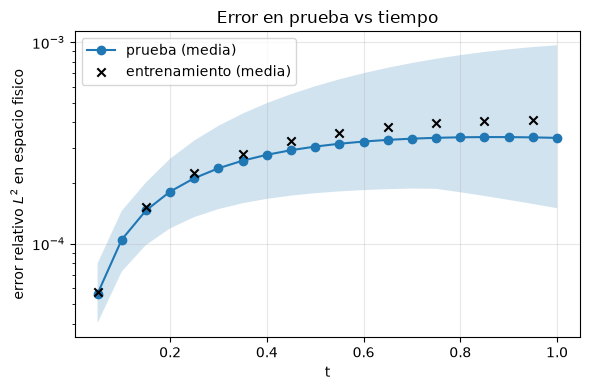

,prueba
mse,3.535272e-11
rmse,5.945816e-06
mae,2.328413e-06
max_error,1.022401e-04
rel_l2,2.538824e-04
r2,9.999999e-01
rel_l2_fisico_medio,2.691324e-04
rel_l2_fisico_max,9.658012e-04


In [10]:
display(exp_0_5.test())

## 5. Curvas de entrenamiento

Perdida total de `evaluate_split` (incluye $\mathcal{{L}}_{{\text{{class}}}}$) y error relativo; la linea punteada marca la epoca que restauro el early stopping.

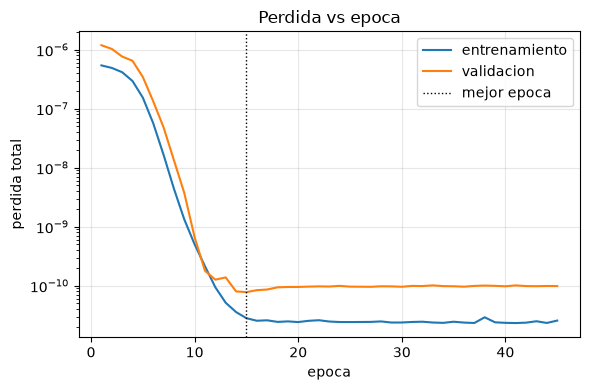

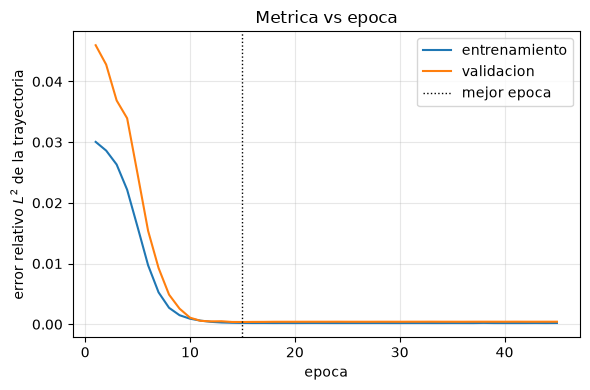

In [11]:
exp_0_5.curves()

## 6. Simbolo aprendido vs. referencia

Simbolo frente a $|\mathbf{k}|^{0.5}$ en $|k_i|\le k_{\max}$: curva contra $|k|$, paridad y error absoluto contra $k$.

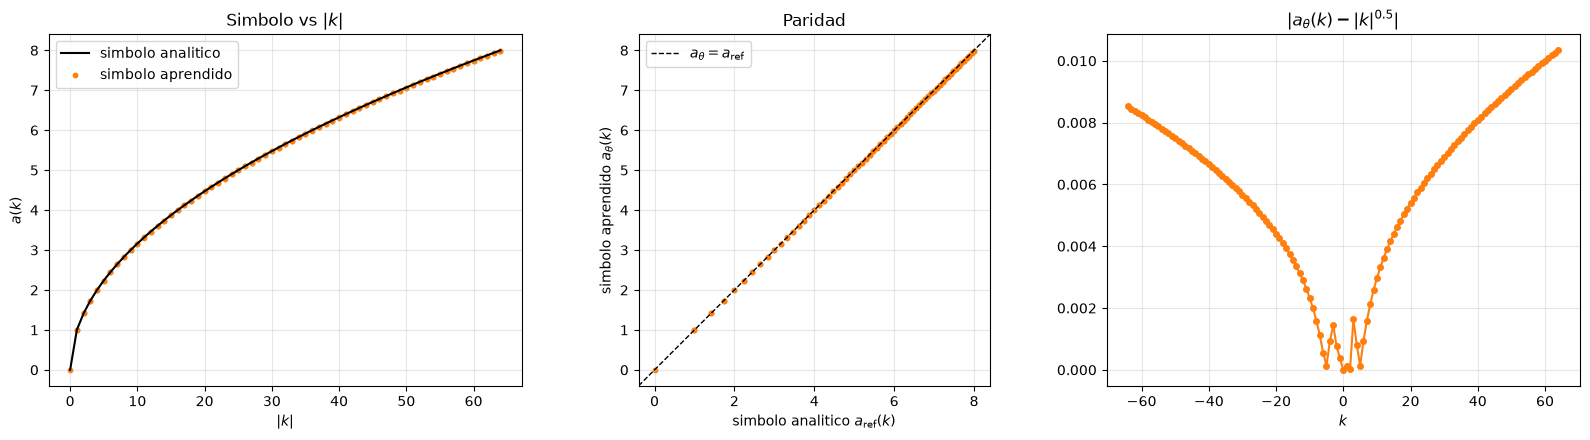

error relativo medio = 0.001, maximo = 0.001  (|k_i| <= 64, k = 0 excluido del cociente)


In [12]:
exp_0_5.symbol_figure()

## 7. Certificacion de parabolicidad

Rejilla independiente de la de entrenamiento: $|\lambda|$ log-espaciado en $[10^{-2},10^3]$ con $25$ angulos en $[-\pi/2,\pi/2]$, y $|k_i|\le K$ con $K=k_{\max}$ (dentro de la ventana), $2k_{\max}$ y $3k_{\max}$ (fuera).

In [13]:
display(exp_0_5.certification())

ParabolicMLPSymbol(c=0.7568, C=1.1, hidden=(32, 32), sin dropout)(n=1, m=0.5, rho=2, dim=1)
kappa usada = 2.0000
rejilla de certificacion: |k_i| <= K x 625 lambda (|lambda| en [1e-2, 1e3], Re(lambda) >= 0)
kappa minimo que certificaria |k_i| <= 192: 1.1893


,K,region,puntos,max_ratio,satisfecha
0,64,dentro,80625,0.594649,True
1,128,fuera,160625,0.594649,True
2,192,fuera,240625,0.594649,True


## 8. Clase del simbolo: $S^{m,\rho}$

`SymbolClassVerifier` estima $\hat C_\alpha(K)$ en ventanas crecientes y la pendiente log-log. **Es evidencia en una ventana finita, no una prueba.**

In [14]:
display(exp_0_5.symbol_class())

consistentes: 3 de 3 multiindices (rho = 2, m = 0.5)
ventana explorada: |k_i| <= 128 (evidencia, no prueba sobre todo Z^n)
pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta


,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(128),crecim.(12->128),pendiente,m-|alpha|,estable,consistente
0,"(0,)",0,0.985411,0.995571,0.997437,0.998913,1.001479,0.500053,0.5,True,True
1,"(1,)",1,1.189646,1.189646,1.189646,1.189646,1.000000,-0.502815,-0.5,True,True
2,"(2,)",2,3.363993,3.363993,3.363993,3.363993,1.000000,-1.516857,-1.5,True,True


# $\alpha = 1$

$a(\mathbf{k})=|\mathbf{k}|^{1}$, $m=1$, malla 1024 puntos, $k_{\text{cap}}=64$. Tablas y figuras en `results/05_fraccionario_1d/alpha_1/`.

In [15]:
exp_1_0 = experimentos[1.0]

## 1. Datos de referencia

Ventana de $k$ resultante y numero de muestras por conjunto.

In [16]:
display(exp_1_0.load_data())

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 1142 de 10240 pares (k, t) recuperables (eps=2.22e-16, |k|_inf <= 64) -> 114,200 muestras
  ventana de k recuperable: 129 k, |k|_inf <= 64, |k| in [0, 64]
  max |k| por tiempo: t=0.05:64, t=0.15:64, t=0.25:64, t=0.35:64, t=0.45:64, t=0.55:64, t=0.65:55, t=0.75:48, t=0.85:42, t=0.95:37
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 2256 de 20480 pares (k, t) recuperables (eps=2.22e-16, |k|_inf <= 64) -> 45,120 muestras
  ventana de k recuperable: 129 k, |k|_inf <= 64, |k| in [0, 64]
  max |k| por tiempo: t=0.05:64, t=0.10:64, t=0.15:64, t=0.20:64, t=0.25:64, t=0.30:64, t=0.35:64, t=0.40:64, t=0.45:64, t=0.50:64, t=0.55:64, t=0.60:60, t=0.65:55, t=0.70:51, t=0.75:48, t=0.80:45, t=0.85:42, t=0.90:40, t=0.95:37, t=1.00:36

k_cap = 64  ->  k_max = 64  (ventana recuperable: 129 k, |k|_inf <= 64, |k| in [0, 64])


,muestras,k_unicos
conjunto,,
entrenamiento,90900,103
validacion,23300,26
prueba,45120,129


## 2. $\kappa$ teorico y constantes $C_\alpha$

$c$ y $C$ se estiman solo con los datos de entrenamiento y fijan $\kappa=$ `theoretical_kappa()`. $\hat\kappa$ del simbolo de referencia se calcula solo como comparacion.

In [17]:
display(exp_1_0.estimate_constants())

estimate_symbol: 75,100 de 90,900 pares (k, t) recuperables (tol=1e-10); 103 de 103 k de entrenamiento
  ventana usada: 103 k, |k|_inf <= 64, |k| in [0, 64]
kappa_hat referencia = 1.4142
(c, C) de los datos  = (0.6364, 1.0999)   m = 1, ventana: 102 k, |k|_inf <= 64, |k| in [1, 64]
kappa teorico        = 2.2222


,C_alpha (x1.5)
alpha,
"(0,)",1.499817
"(1,)",1.500000
"(2,)",4.242641


## 3. Barrido de hiperparametros

$3$ profundidades $\times$ $3$ anchos $\times$ ubicacion del dropout $\times$ $2$ weight decays $=$ **30 entrenamientos** (con $2$ capas, `middle` equivale a `none` y no se repite).

In [18]:
exp_1_0.sweep()

[  1/30] 2x32  drop[-] wd=0e+00 | rel_l2=0.0015 |  21.6s
[  2/30] 2x32  drop[-] wd=1e-04 | rel_l2=0.0015 |  21.8s
[  3/30] 2x64  drop[-] wd=0e+00 | rel_l2=0.0013 |  21.9s
[  4/30] 2x64  drop[-] wd=1e-04 | rel_l2=0.0013 |  21.6s
[  5/30] 2x128 drop[-] wd=0e+00 | rel_l2=0.0013 |  32.8s
[  6/30] 2x128 drop[-] wd=1e-04 | rel_l2=0.0013 |  32.9s
[  7/30] 3x32  drop[-] wd=0e+00 | rel_l2=0.0037 |  20.3s
[  8/30] 3x32  drop[-] wd=1e-04 | rel_l2=0.0037 |  20.2s
[  9/30] 3x32  drop[1] wd=0e+00 | rel_l2=0.0723 |  21.5s
[ 10/30] 3x32  drop[1] wd=1e-04 | rel_l2=0.0723 |  21.9s
[ 11/30] 3x64  drop[-] wd=0e+00 | rel_l2=0.0019 |  20.7s
[ 12/30] 3x64  drop[-] wd=1e-04 | rel_l2=0.0019 |  20.5s
[ 13/30] 3x64  drop[1] wd=0e+00 | rel_l2=0.0646 |  20.9s
[ 14/30] 3x64  drop[1] wd=1e-04 | rel_l2=0.0646 |  21.3s
[ 15/30] 3x128 drop[-] wd=0e+00 | rel_l2=0.0015 |  57.9s
[ 16/30] 3x128 drop[-] wd=1e-04 | rel_l2=0.0015 |  58.0s
[ 17/30] 3x128 drop[1] wd=0e+00 | rel_l2=0.0639 |  42.5s
[ 18/30] 3x128 drop[1] wd=1e-04

## 4. Resultados del barrido

In [19]:
barrido, por_eje = exp_1_0.sweep_results()
display(barrido)
for tabla in por_eje:
    display(tabla)

30 corridas, 16.2 min de entrenamiento en total


,capas,ancho,dropout,weight_decay,val_rel_l2,val_total,val_par_max_ratio
0,2,128,OFF,0.0000,0.001302,6.437906e-10,0.637910
1,2,128,OFF,0.0001,0.001302,6.438987e-10,0.637909
2,2,64,OFF,0.0000,0.001324,6.651315e-10,0.638548
3,2,64,OFF,0.0001,0.001324,6.654366e-10,0.638548
4,2,32,OFF,0.0000,0.001451,7.994224e-10,0.637458
5,2,32,OFF,0.0001,0.001452,8.002109e-10,0.637458
6,3,128,OFF,0.0001,0.001481,8.322452e-10,0.636474
7,3,128,OFF,0.0000,0.001482,8.332117e-10,0.636475
8,3,64,OFF,0.0001,0.001870,1.327290e-09,0.640028
9,3,64,OFF,0.0000,0.001871,1.328406e-09,0.640028


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
dropout,,,,
OFF,18,0.001302,6.437906e-10,0.636360
"ON p=0.2 capas[1,2]",6,0.031665,3.806380e-07,0.510756
ON p=0.2 capas[1],6,0.063915,1.550805e-06,0.526532


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
weight_decay,,,,
0.0000,15,0.001302,6.437906e-10,0.510756
0.0001,15,0.001302,6.438987e-10,0.510756


### Seleccion: la mejor aproximacion

Todas las corridas usan $\kappa=$ `theoretical_kappa()`, asi que se elige la de **menor error relativo de validacion**.

In [20]:
display(exp_1_0.select())

kappa = theoretical_kappa() = 2.2222
kappa_hat aprendido         = 1.4176   (certificacion, |k_i| <= 192)
kappa_hat referencia        = 1.4142   (simbolo analitico)
arquitectura elegida    = 2 capas x 128 neuronas
dropout                 = OFF
weight decay            = 0  (Linear ocultas interiores)
early stopping          = mejor epoca 9 de 39 corridas


total                   6.437906e-10
trayectoria             6.437906e-10
parabolicidad           0.000000e+00
clase                   0.000000e+00
rel_l2                  1.302259e-03
peor ratio              6.379096e-01
puntos con ratio > 1    0.000000e+00
Name: validacion (mejor epoca), dtype: float64

### Metricas del modelo seleccionado

Trayectoria sobre las muestras de entrenamiento y validacion, y simbolo $a_\theta(\mathbf{{k}})$ frente a $|\mathbf{k}|^{1}$ sobre los $k$ de entrenamiento y los de validacion (que la red nunca vio).

In [21]:
traj, sym = exp_1_0.metrics()
display(traj)
display(sym)

TRAYECTORIA -- muestras: 90,900 entrenamiento / 23,300 validacion; SIMBOLO -- k unicos: 103 entrenamiento / 26 validacion


,entrenamiento,validacion
mse,2.424634e-09,6.437906e-10
rmse,4.924057e-05,2.537303e-05
mae,1.387489e-05,9.524162e-06
max_error,8.902312e-04,2.302486e-04
rel_l2,2.066858e-03,1.302259e-03
r2,9.999957e-01,9.999983e-01


,entrenamiento,validacion
mse,0.135766,0.118291
rmse,0.368465,0.343935
mae,0.296035,0.263767
max_error,0.813835,0.775389
rel_l2,0.009877,0.009302


### Evaluacion en prueba

Error relativo $L^2$ sobre los pares $(k,t)$ recuperables de prueba y en espacio fisico (malla completa, todos los modos), por condicion inicial y tiempo.

PRUEBA -- 45,120 pares recuperables, 20 condiciones iniciales nuevas
error relativo L2 (pares recuperables) = 2.2867e-03
error relativo L2 (espacio fisico)     = 1.6749e-03  (medio; max 4.8874e-03)


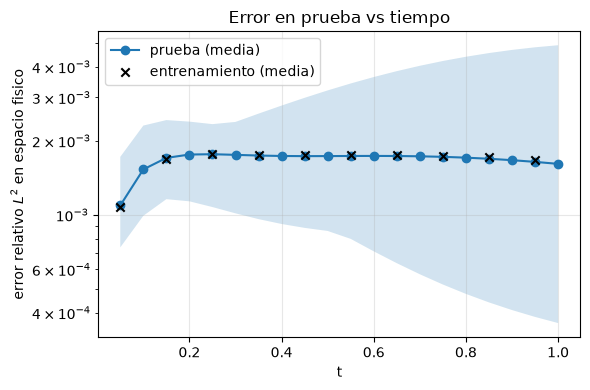

,prueba
mse,2.560846e-09
rmse,5.060480e-05
mae,1.275354e-05
max_error,9.455248e-04
rel_l2,2.286746e-03
r2,9.999948e-01
rel_l2_fisico_medio,1.674904e-03
rel_l2_fisico_max,4.887374e-03


In [22]:
display(exp_1_0.test())

## 5. Curvas de entrenamiento

Perdida total de `evaluate_split` (incluye $\mathcal{{L}}_{{\text{{class}}}}$) y error relativo; la linea punteada marca la epoca que restauro el early stopping.

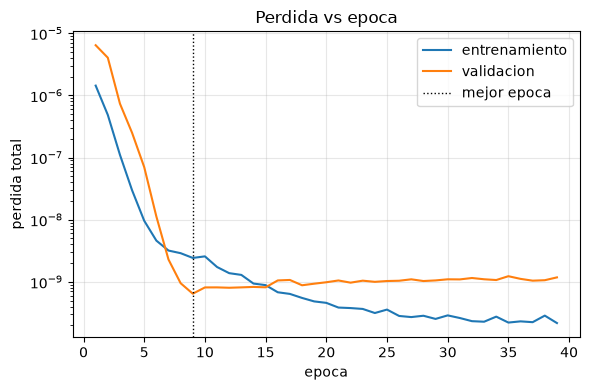

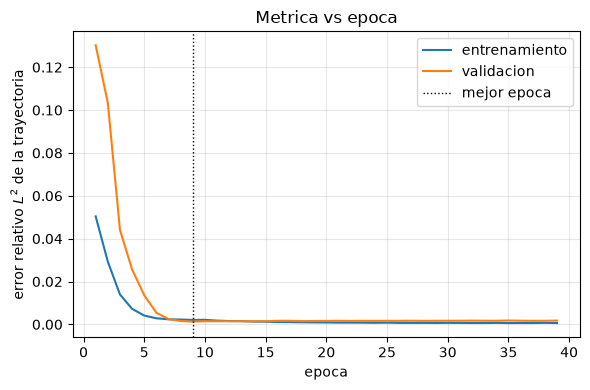

In [23]:
exp_1_0.curves()

## 6. Simbolo aprendido vs. referencia

Simbolo frente a $|\mathbf{k}|^{1}$ en $|k_i|\le k_{\max}$: curva contra $|k|$, paridad y error absoluto contra $k$.

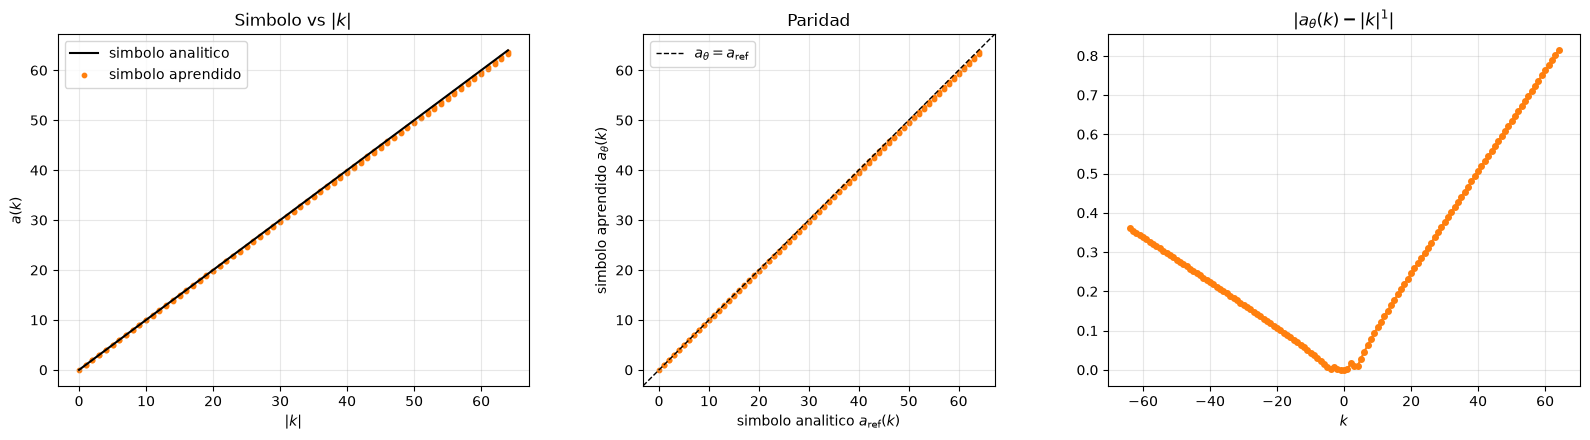

error relativo medio = 0.008, maximo = 0.013  (|k_i| <= 64, k = 0 excluido del cociente)


In [24]:
exp_1_0.symbol_figure()

## 7. Certificacion de parabolicidad

Rejilla independiente de la de entrenamiento: $|\lambda|$ log-espaciado en $[10^{-2},10^3]$ con $25$ angulos en $[-\pi/2,\pi/2]$, y $|k_i|\le K$ con $K=k_{\max}$ (dentro de la ventana), $2k_{\max}$ y $3k_{\max}$ (fuera).

In [25]:
display(exp_1_0.certification())

ParabolicMLPSymbol(c=0.6364, C=1.1, hidden=(128, 128), sin dropout)(n=1, m=1.0, rho=2, dim=1)
kappa usada = 2.2222
rejilla de certificacion: |k_i| <= K x 625 lambda (|lambda| en [1e-2, 1e3], Re(lambda) >= 0)
kappa minimo que certificaria |k_i| <= 192: 1.4176


,K,region,puntos,max_ratio,satisfecha
0,64,dentro,80625,0.63794,True
1,128,fuera,160625,0.63794,True
2,192,fuera,240625,0.63794,True


## 8. Clase del simbolo: $S^{m,\rho}$

`SymbolClassVerifier` estima $\hat C_\alpha(K)$ en ventanas crecientes y la pendiente log-log. **Es evidencia en una ventana finita, no una prueba.**

In [26]:
display(exp_1_0.symbol_class())

consistentes: 3 de 3 multiindices (rho = 2, m = 1)
ventana explorada: |k_i| <= 128 (evidencia, no prueba sobre todo Z^n)
pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta


,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(128),crecim.(12->128),pendiente,m-|alpha|,estable,consistente
0,"(0,)",0,0.970438,0.988547,0.991780,0.994313,1.002554,1.000092,1.0,True,True
1,"(1,)",1,1.019248,1.019248,1.019248,1.019248,1.000000,0.000033,0.0,True,True
2,"(2,)",2,2.826142,2.826142,2.826142,2.826142,1.000000,-2.964204,-1.0,True,True


# $\alpha = 1.5$

$a(\mathbf{k})=|\mathbf{k}|^{1.5}$, $m=1.5$, malla 1024 puntos, $k_{\text{cap}}=64$. Tablas y figuras en `results/05_fraccionario_1d/alpha_1.5/`.

In [27]:
exp_1_5 = experimentos[1.5]

## 1. Datos de referencia

Ventana de $k$ resultante y numero de muestras por conjunto.

In [28]:
display(exp_1_5.load_data())

ENTRENAMIENTO
100 condiciones iniciales x 10 tiempos, resolucion 1024: 478 de 10240 pares (k, t) recuperables (eps=2.22e-16, |k|_inf <= 64) -> 47,800 muestras
  ventana de k recuperable: 129 k, |k|_inf <= 64, |k| in [0, 64]
  max |k| por tiempo: t=0.05:64, t=0.15:38, t=0.25:27, t=0.35:21, t=0.45:18, t=0.55:16, t=0.65:14, t=0.75:13, t=0.85:12, t=0.95:11
PRUEBA
20 condiciones iniciales x 20 tiempos, resolucion 1024: 894 de 20480 pares (k, t) recuperables (eps=2.22e-16, |k|_inf <= 64) -> 17,880 muestras
  ventana de k recuperable: 129 k, |k|_inf <= 64, |k| in [0, 64]
  max |k| por tiempo: t=0.05:64, t=0.10:50, t=0.15:38, t=0.20:31, t=0.25:27, t=0.30:24, t=0.35:21, t=0.40:20, t=0.45:18, t=0.50:17, t=0.55:16, t=0.60:15, t=0.65:14, t=0.70:13, t=0.75:13, t=0.80:12, t=0.85:12, t=0.90:11, t=0.95:11, t=1.00:10

k_cap = 64  ->  k_max = 64  (ventana recuperable: 129 k, |k|_inf <= 64, |k| in [0, 64])


,muestras,k_unicos
conjunto,,
entrenamiento,37800,103
validacion,10000,26
prueba,17880,129


## 2. $\kappa$ teorico y constantes $C_\alpha$

$c$ y $C$ se estiman solo con los datos de entrenamiento y fijan $\kappa=$ `theoretical_kappa()`. $\hat\kappa$ del simbolo de referencia se calcula solo como comparacion.

In [29]:
display(exp_1_5.estimate_constants())

estimate_symbol: 29,600 de 37,800 pares (k, t) recuperables (tol=1e-10); 96 de 103 k de entrenamiento
  ventana usada: 96 k, |k|_inf <= 59, |k| in [0, 59]
kappa_hat referencia = 1.6818
(c, C) de los datos  = (0.5351, 1.0998)   m = 1.5, ventana: 95 k, |k|_inf <= 59, |k| in [1, 59]
kappa teorico        = 2.6427


,C_alpha (x1.5)
alpha,
"(0,)",1.499725
"(1,)",2.375090
"(2,)",3.567621


## 3. Barrido de hiperparametros

$3$ profundidades $\times$ $3$ anchos $\times$ ubicacion del dropout $\times$ $2$ weight decays $=$ **30 entrenamientos** (con $2$ capas, `middle` equivale a `none` y no se repite).

In [30]:
exp_1_5.sweep()

[  1/30] 2x32  drop[-] wd=0e+00 | rel_l2=0.0034 |  17.1s
[  2/30] 2x32  drop[-] wd=1e-04 | rel_l2=0.0034 |  15.9s
[  3/30] 2x64  drop[-] wd=0e+00 | rel_l2=0.0025 |  14.5s
[  4/30] 2x64  drop[-] wd=1e-04 | rel_l2=0.0025 |  13.6s
[  5/30] 2x128 drop[-] wd=0e+00 | rel_l2=0.0023 |  18.0s
[  6/30] 2x128 drop[-] wd=1e-04 | rel_l2=0.0023 |  18.1s
[  7/30] 3x32  drop[-] wd=0e+00 | rel_l2=0.0081 |  11.2s
[  8/30] 3x32  drop[-] wd=1e-04 | rel_l2=0.0081 |  11.2s
[  9/30] 3x32  drop[1] wd=0e+00 | rel_l2=0.0972 |   6.7s
[ 10/30] 3x32  drop[1] wd=1e-04 | rel_l2=0.0972 |   6.9s
[ 11/30] 3x64  drop[-] wd=0e+00 | rel_l2=0.0049 |  10.4s
[ 12/30] 3x64  drop[-] wd=1e-04 | rel_l2=0.0049 |  10.4s
[ 13/30] 3x64  drop[1] wd=0e+00 | rel_l2=0.0863 |   7.7s
[ 14/30] 3x64  drop[1] wd=1e-04 | rel_l2=0.0863 |   7.7s
[ 15/30] 3x128 drop[-] wd=0e+00 | rel_l2=0.0038 |  23.7s
[ 16/30] 3x128 drop[-] wd=1e-04 | rel_l2=0.0038 |  23.7s
[ 17/30] 3x128 drop[1] wd=0e+00 | rel_l2=0.0786 |  18.6s
[ 18/30] 3x128 drop[1] wd=1e-04

## 4. Resultados del barrido

In [31]:
barrido, por_eje = exp_1_5.sweep_results()
display(barrido)
for tabla in por_eje:
    display(tabla)

30 corridas, 7.9 min de entrenamiento en total


,capas,ancho,dropout,weight_decay,val_rel_l2,val_total,val_par_max_ratio
0,2,128,OFF,0.0000,0.002344,2.922038e-09,0.657450
1,2,128,OFF,0.0001,0.002344,2.922661e-09,0.657450
2,2,64,OFF,0.0000,0.002494,3.308647e-09,0.656347
3,2,64,OFF,0.0001,0.002494,3.308750e-09,0.656347
4,2,32,OFF,0.0001,0.003375,6.058848e-09,0.657840
5,2,32,OFF,0.0000,0.003376,6.059466e-09,0.657841
6,3,128,OFF,0.0000,0.003765,7.537481e-09,0.663822
7,3,128,OFF,0.0001,0.003765,7.537725e-09,0.663821
8,3,64,OFF,0.0001,0.004886,1.269352e-08,0.661382
9,3,64,OFF,0.0000,0.004886,1.269581e-08,0.661382


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
dropout,,,,
OFF,18,0.002344,2.922038e-09,0.655561
"ON p=0.2 capas[1,2]",6,0.044108,1.034542e-06,0.496483
ON p=0.2 capas[1],6,0.078598,3.285102e-06,0.511471


,corridas,mejor_val_rel_l2,mejor_val_total,peor_ratio
weight_decay,,,,
0.0000,15,0.002344,2.922038e-09,0.496483
0.0001,15,0.002344,2.922661e-09,0.496483


### Seleccion: la mejor aproximacion

Todas las corridas usan $\kappa=$ `theoretical_kappa()`, asi que se elige la de **menor error relativo de validacion**.

In [32]:
display(exp_1_5.select())

kappa = theoretical_kappa() = 2.6427
kappa_hat aprendido         = 1.7359   (certificacion, |k_i| <= 192)
kappa_hat referencia        = 1.6818   (simbolo analitico)
arquitectura elegida    = 2 capas x 128 neuronas
dropout                 = OFF
weight decay            = 0  (Linear ocultas interiores)
early stopping          = mejor epoca 19 de 49 corridas


total                   2.922038e-09
trayectoria             2.922038e-09
parabolicidad           0.000000e+00
clase                   0.000000e+00
rel_l2                  2.344129e-03
peor ratio              6.574503e-01
puntos con ratio > 1    0.000000e+00
Name: validacion (mejor epoca), dtype: float64

### Metricas del modelo seleccionado

Trayectoria sobre las muestras de entrenamiento y validacion, y simbolo $a_\theta(\mathbf{{k}})$ frente a $|\mathbf{k}|^{1.5}$ sobre los $k$ de entrenamiento y los de validacion (que la red nunca vio).

In [33]:
traj, sym = exp_1_5.metrics()
display(traj)
display(sym)

TRAYECTORIA -- muestras: 37,800 entrenamiento / 10,000 validacion; SIMBOLO -- k unicos: 103 entrenamiento / 26 validacion


,entrenamiento,validacion
mse,9.158279e-09,2.922038e-09
rmse,9.569890e-05,5.405587e-05
mae,3.301617e-05,2.075175e-05
max_error,1.265988e-03,6.070793e-04
rel_l2,2.737197e-03,2.344129e-03
r2,9.999925e-01,9.999945e-01


,entrenamiento,validacion
mse,35.332235,32.310102
rmse,5.944092,5.684198
mae,4.626248,4.342451
max_error,13.959582,12.985607
rel_l2,0.022901,0.022140


### Evaluacion en prueba

Error relativo $L^2$ sobre los pares $(k,t)$ recuperables de prueba y en espacio fisico (malla completa, todos los modos), por condicion inicial y tiempo.

PRUEBA -- 17,880 pares recuperables, 20 condiciones iniciales nuevas
error relativo L2 (pares recuperables) = 2.7253e-03
error relativo L2 (espacio fisico)     = 1.7949e-03  (medio; max 5.5229e-03)


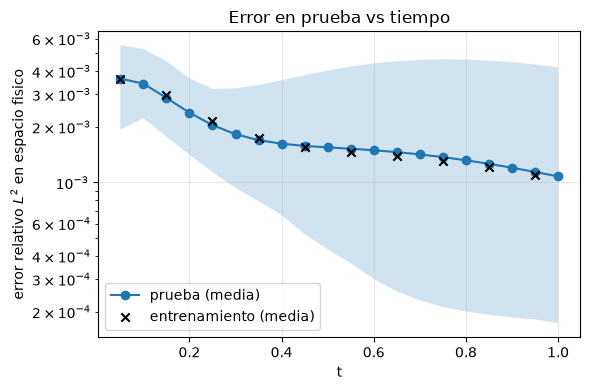

,prueba
mse,7.758930e-09
rmse,8.808479e-05
mae,2.859673e-05
max_error,9.780100e-04
rel_l2,2.725306e-03
r2,9.999925e-01
rel_l2_fisico_medio,1.794879e-03
rel_l2_fisico_max,5.522887e-03


In [34]:
display(exp_1_5.test())

## 5. Curvas de entrenamiento

Perdida total de `evaluate_split` (incluye $\mathcal{{L}}_{{\text{{class}}}}$) y error relativo; la linea punteada marca la epoca que restauro el early stopping.

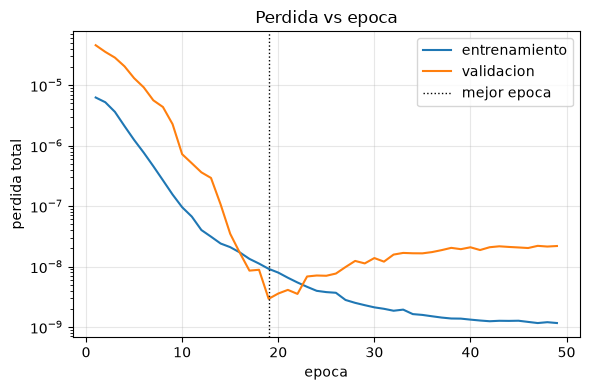

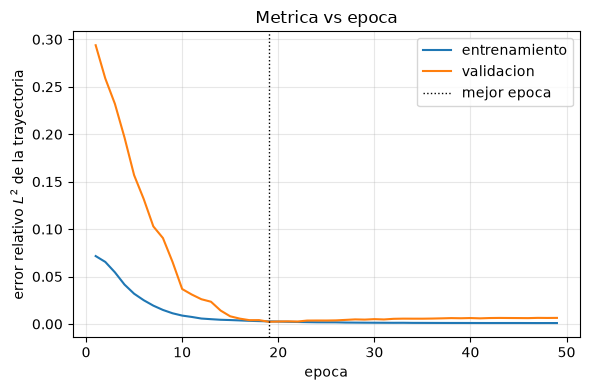

In [35]:
exp_1_5.curves()

## 6. Simbolo aprendido vs. referencia

Simbolo frente a $|\mathbf{k}|^{1.5}$ en $|k_i|\le k_{\max}$: curva contra $|k|$, paridad y error absoluto contra $k$.

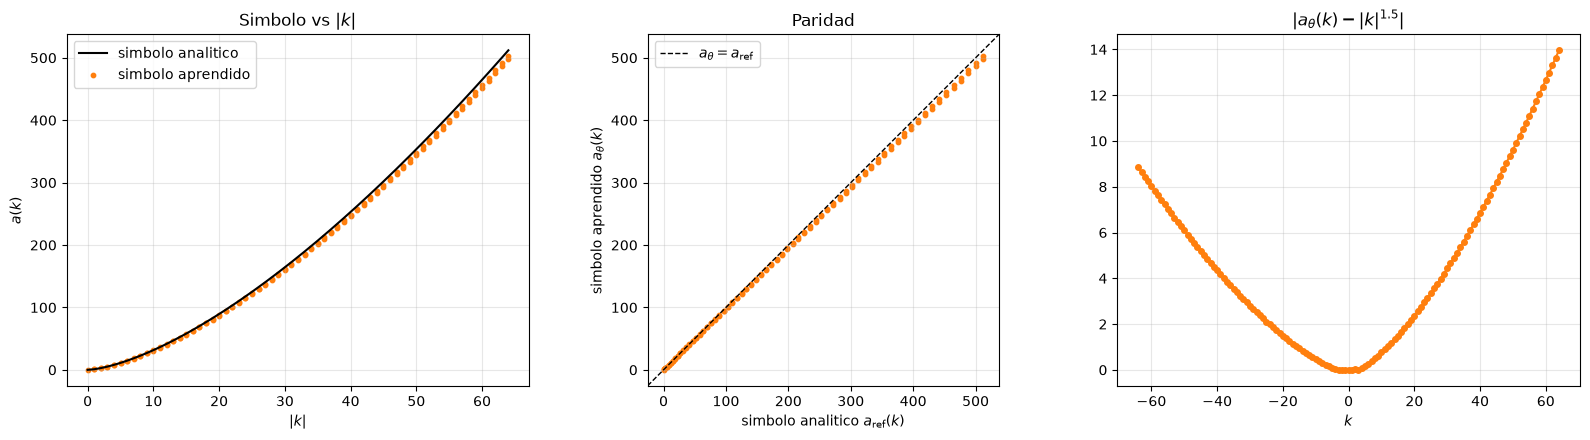

error relativo medio = 0.020, maximo = 0.027  (|k_i| <= 64, k = 0 excluido del cociente)


In [36]:
exp_1_5.symbol_figure()

## 7. Certificacion de parabolicidad

Rejilla independiente de la de entrenamiento: $|\lambda|$ log-espaciado en $[10^{-2},10^3]$ con $25$ angulos en $[-\pi/2,\pi/2]$, y $|k_i|\le K$ con $K=k_{\max}$ (dentro de la ventana), $2k_{\max}$ y $3k_{\max}$ (fuera).

In [37]:
display(exp_1_5.certification())

ParabolicMLPSymbol(c=0.5351, C=1.1, hidden=(128, 128), sin dropout)(n=1, m=1.5, rho=2, dim=1)
kappa usada = 2.6427
rejilla de certificacion: |k_i| <= K x 625 lambda (|lambda| en [1e-2, 1e3], Re(lambda) >= 0)
kappa minimo que certificaria |k_i| <= 192: 1.7359


,K,region,puntos,max_ratio,satisfecha
0,64,dentro,80625,0.656863,True
1,128,fuera,160625,0.656863,True
2,192,fuera,240625,0.656863,True


## 8. Clase del simbolo: $S^{m,\rho}$

`SymbolClassVerifier` estima $\hat C_\alpha(K)$ en ventanas crecientes y la pendiente log-log. **Es evidencia en una ventana finita, no una prueba.**

In [38]:
display(exp_1_5.symbol_class())

consistentes: 3 de 3 multiindices (rho = 2, m = 1.5)
ventana explorada: |k_i| <= 128 (evidencia, no prueba sobre todo Z^n)
pendiente = nan significa Delta^alpha a = 0 en la ventana, asi que C_alpha = 0 basta


,alpha,|alpha|,C_hat(4),C_hat(8),C_hat(12),C_hat(128),crecim.(12->128),pendiente,m-|alpha|,estable,consistente
0,"(0,)",0,0.952414,0.975476,0.979495,0.982623,1.003194,1.500114,1.5,True,True
1,"(1,)",1,1.570413,1.570413,1.570413,1.570413,1.000000,0.502861,0.5,True,True
2,"(2,)",2,2.377220,2.377220,2.377220,2.377220,1.000000,-0.505728,-0.5,True,True


# Resumen

Una fila por $\alpha$: ventana de $k$, $c$, $C$, $\kappa$, configuracion elegida, error relativo de validacion, error en prueba (pares recuperables y espacio fisico), error relativo medio del simbolo en $|k_i|\le k_{\max}$, peor ratio de la certificacion (en las tres ventanas) y multiindices consistentes. Se guarda en `resumen.csv`.

In [39]:
display(summary_table(experimentos, RESULTS))

,alpha,ventana_k,c,C,kappa,configuracion,val_rel_l2,test_rel_l2,test_rel_l2_fisico,error_simbolo_medio,peor_ratio,multiindices_consistentes
0,0.5,"129 k, |k|_inf <= 64, |k| in [0, 64]",0.756807,1.099933,2.000000,"2x32, dropout OFF, wd=0.0001",0.000371,0.000254,0.000269,0.001027,0.594649,3/3
1,1.0,"129 k, |k|_inf <= 64, |k| in [0, 64]",0.636396,1.099866,2.222222,"2x128, dropout OFF, wd=0",0.001302,0.002287,0.001675,0.008242,0.637940,3/3
2,1.5,"129 k, |k|_inf <= 64, |k| in [0, 64]",0.535143,1.099763,2.642682,"2x128, dropout OFF, wd=0",0.002344,0.002725,0.001795,0.020064,0.656863,3/3
